# AutoMove City — Interpolación de demanda con splines cúbicos
Este cuaderno implementa:

1. **Interpolación** de los 10 reportes de demanda con `scipy.interpolate.CubicSpline` (condición **periódica** vs **natural**, con la interpolación lineal como referencia).
2. **Cálculo numérico adicional** sobre la curva de 1440 minutos:
   - derivación (analítica de la spline vs. diferencias finitas) → tasas de cambio y punto pico,
   - integración (exacta de la spline vs. trapecio y Simpson) → solicitudes totales del día,
   - **detección del umbral** de 150 solicitudes/min (raíces exactas y minutos discretos).
3. **Gráficas comparativas.**
4. **Mejora tecnológica — Filtro Predictivo de Corto Plazo:** suavizado exponencial / media móvil ponderada sobre la desviación respecto a la spline, con proyección a 30 min y **alertas automáticas** cuando la demanda proyectada supera 150 solicitudes/min.

> Convención: $t$ en horas decimales, $D(t)$ en solicitudes/min. El minuto $k$ del día corresponde a $t_k = k/60$, $k = 0,\dots,1439$.

In [3]:
from collections import deque
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import simpson, trapezoid
from scipy.interpolate import CubicSpline

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Rutas (el cuaderno puede ejecutarse desde la raíz o desde algorithm/)
RAIZ = Path.cwd().resolve()
if not (RAIZ / "data").exists():
    RAIZ = RAIZ.parent
DATA_CSV = RAIZ / "data" / "data.csv"
FIG_DIR = RAIZ / "assets" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

UMBRAL = 150.0           # solicitudes/min (umbral crítico)
MIN_DIA = 1440           # minutos en un día
T_CIERRE = 24.0          # nodo de cierre periódico


def hhmm(t_horas, segundos=False):
    # Convierte horas decimales a 'HH:MM' (o 'HH:MM:SS').
    total_s = int(round(float(t_horas) * 3600))
    h, rem = divmod(total_s, 3600)
    m, s = divmod(rem, 60)
    return f"{h:02d}:{m:02d}:{s:02d}" if segundos else f"{h:02d}:{m:02d}"


def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight", dpi=200)

## 1. Datos y nodo de cierre periódico

Según la nota técnica del enunciado, el ciclo diario se cierra en $t = 24.0$ h con el mismo valor de $t = 0.0$ h (15 solicitudes/min). Este nodo adicional es requisito de `bc_type='periodic'` ($y_0 = y_n$).

In [4]:
df = pd.read_csv(DATA_CSV, skipinitialspace=True)
df.columns = df.columns.str.strip()

t_nodos = np.append(df["hora"].to_numpy(float), T_CIERRE)
y_nodos = np.append(df["demanda"].to_numpy(float), df["demanda"].iloc[0])

nodos = pd.DataFrame({"nodo": [str(i) for i in range(1, len(t_nodos))] + ["cierre"],
                      "hora (h)": t_nodos, "demanda (sol/min)": y_nodos})
print("Espaciado h_i entre nodos (no equidistante):", np.diff(t_nodos))
nodos

Espaciado h_i entre nodos (no equidistante): [1.5 1.5 3.  3.  3.  3.  3.  1.5 1.5 3. ]


,nodo,hora (h),demanda (sol/min)
0,1,0.0,15.0
1,2,1.5,18.0
2,3,3.0,12.0
3,4,6.0,45.0
4,5,9.0,120.0
5,6,12.0,180.0
6,7,15.0,150.0
7,8,18.0,98.0
8,9,19.5,75.0
9,10,21.0,55.0


## 2. Construcción de las splines

En cada subintervalo $[t_i, t_{i+1}]$ la spline es un polinomio cúbico

$$
S_i(t) = a_i + b_i\,(t - t_i) + c_i\,(t - t_i)^2 + d_i\,(t - t_i)^3,
$$

con $S \in C^2[0, 24]$. Las condiciones de frontera comparadas son:

| Condición | Ecuaciones extra | Interpretación |
|---|---|---|
| **Periódica** | $S'(0) = S'(24)$, $S''(0) = S''(24)$ | el día termina igual que empieza: la curva se “empalma” sin quiebres a medianoche |
| **Natural** | $S''(0) = S''(24) = 0$ | extremos libres; no garantiza continuidad de la pendiente al pasar de un día al siguiente |

In [5]:
spline_per = CubicSpline(t_nodos, y_nodos, bc_type="periodic")
spline_nat = CubicSpline(t_nodos, y_nodos, bc_type="natural")
lineal = lambda t: np.interp(t, t_nodos, y_nodos)

# Coeficientes de la spline periódica. scipy guarda c[k, i] para (t - t_i)^(3-k)
coef = pd.DataFrame({
    "intervalo": [f"[{a:g}, {b:g}]" for a, b in zip(t_nodos[:-1], t_nodos[1:])],
    "a_i": spline_per.c[3], "b_i": spline_per.c[2],
    "c_i": spline_per.c[1], "d_i": spline_per.c[0],
})
print("Coeficientes S_i(t) = a_i + b_i (t-t_i) + c_i (t-t_i)^2 + d_i (t-t_i)^3  (periódica)")
coef.round(4)

Coeficientes S_i(t) = a_i + b_i (t-t_i) + c_i (t-t_i)^2 + d_i (t-t_i)^3  (periódica)


,intervalo,a_i,b_i,c_i,d_i
0,"[0, 1.5]",15.0,-1.9495,6.9841,-2.9008
1,"[1.5, 3]",18.0,-0.5773,-6.0694,2.5250
2,"[3, 6]",12.0,-1.7414,5.2933,-0.3487
3,"[6, 9]",45.0,20.6028,2.1547,-0.2297
4,"[9, 12]",120.0,27.3302,0.0877,-0.8437
5,"[12, 15]",180.0,5.0763,-7.5057,0.8268
6,"[15, 18]",150.0,-17.6355,-0.0649,0.0552
7,"[18, 19.5]",98.0,-16.5343,0.4319,0.2458
8,"[19.5, 21]",75.0,-13.5792,1.5381,-0.9161
9,"[21, 24]",55.0,-15.1487,-2.5844,1.0632


In [6]:
# Verificación numérica de continuidad C^2 en nodos interiores y del empalme periódico
eps = 1e-9
filas = []
for orden in range(3):
    f = spline_per.derivative(orden) if orden else spline_per
    salto_int = max(abs(f(ti + eps) - f(ti - eps)) for ti in t_nodos[1:-1])
    salto_per = abs(f(0.0) - f(T_CIERRE))
    fn = spline_nat.derivative(orden) if orden else spline_nat
    salto_nat = abs(fn(0.0) - fn(T_CIERRE))
    filas.append({"derivada": f"S^({orden})", "máx. salto en nodos interiores (periódica)": salto_int,
                  "|S(0)-S(24)| periódica": salto_per, "|S(0)-S(24)| natural": salto_nat})
pd.DataFrame(filas)

,derivada,máx. salto en nodos interiores (periódica),|S(0)-S(24)| periódica,|S(0)-S(24)| natural
0,S^(0),5.466043e-08,0.0,0.000000e+00
1,S^(1),3.002286e-08,0.0,1.760314e+01
2,S^(2),1.305785e-08,0.0,5.606626e-15


La periódica empalma valor, pendiente y curvatura en medianoche (saltos ≈ 0, error de redondeo). La natural solo empalma el valor: la pendiente salta al pasar de las 23:59 a las 00:00.

## 3. Curva de 1440 minutos

In [7]:
minutos = np.arange(MIN_DIA)
t_min = minutos / 60.0                     # 0.0 … 23.983 h

curva = pd.DataFrame({
    "minuto": minutos,
    "hora": [hhmm(t) for t in t_min],
    "t (h)": t_min,
    "periódica": spline_per(t_min),
    "natural": spline_nat(t_min),
    "lineal": lineal(t_min),
})
curva.to_csv(RAIZ / "data" / "curva_1440.csv", index=False)
print(f"{len(curva)} minutos generados; t ∈ [{t_min[0]:.3f}, {t_min[-1]:.3f}] h  → data/curva_1440.csv")
curva.iloc[::120].round(2)

1440 minutos generados; t ∈ [0.000, 23.983] h  → data/curva_1440.csv


,minuto,hora,t (h),periódica,natural,lineal
0,0,00:00,0.0,15.00,15.00,15.00
120,120,02:00,2.0,16.51,16.08,16.00
240,240,04:00,4.0,15.20,15.50,23.00
360,360,06:00,6.0,45.00,45.00,45.00
480,480,08:00,8.0,92.99,92.94,95.00
600,600,10:00,10.0,146.57,146.59,140.00
720,720,12:00,12.0,180.00,180.00,180.00
840,840,14:00,14.0,166.74,166.77,160.00
960,960,16:00,16.0,132.35,132.29,132.67
1080,1080,18:00,18.0,98.00,98.00,98.00


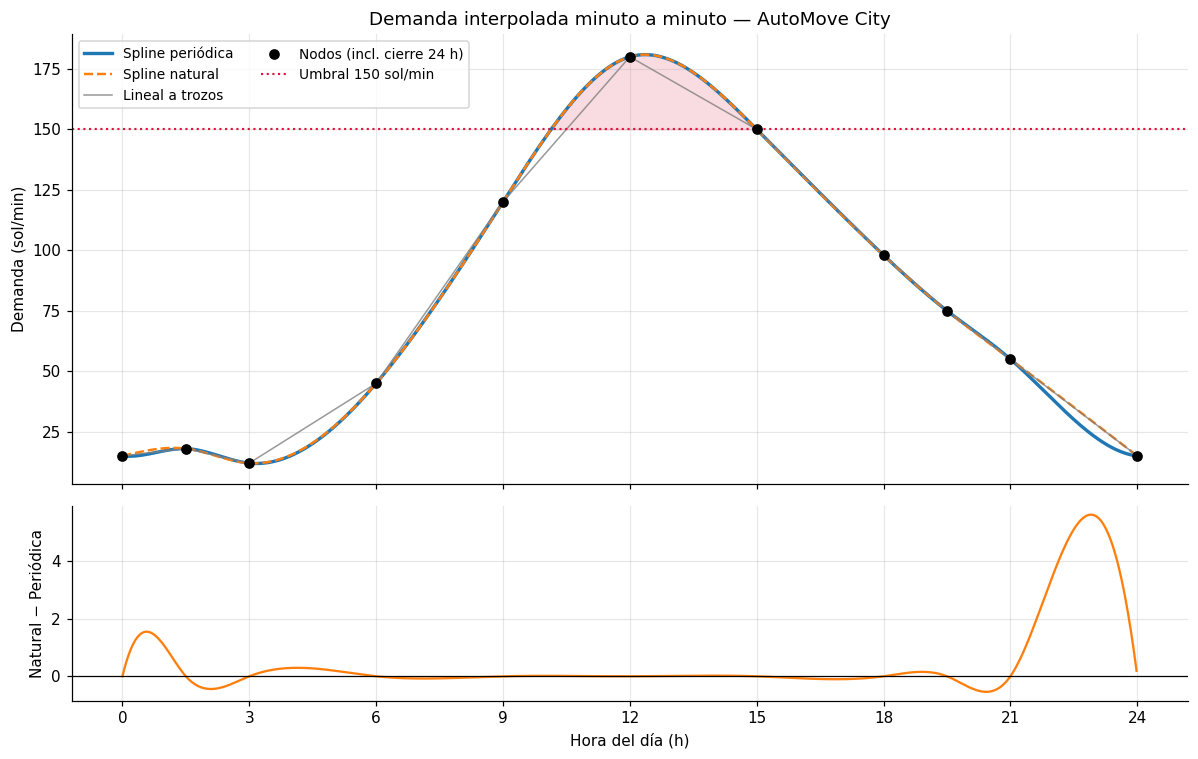

Máx. diferencia natural vs periódica: 5.63 sol/min a las 22:54


In [8]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.3]})

ax.plot(t_min, curva["periódica"], lw=2.2, label="Spline periódica")
ax.plot(t_min, curva["natural"], lw=1.6, ls="--", label="Spline natural")
ax.plot(t_min, curva["lineal"], lw=1, color="gray", alpha=0.8, label="Lineal a trozos")
ax.scatter(t_nodos, y_nodos, color="k", zorder=5, label="Nodos (incl. cierre 24 h)")
ax.axhline(UMBRAL, color="crimson", ls=":", lw=1.4, label=f"Umbral {UMBRAL:.0f} sol/min")
ax.fill_between(t_min, UMBRAL, curva["periódica"], where=curva["periódica"] > UMBRAL,
                color="crimson", alpha=0.15)
ax.set_ylabel("Demanda (sol/min)")
ax.set_title("Demanda interpolada minuto a minuto — AutoMove City")
ax.legend(ncol=2, fontsize=9, loc="upper left")

ax2.plot(t_min, curva["natural"] - curva["periódica"], color="tab:orange")
ax2.axhline(0, color="k", lw=0.8)
ax2.set_ylabel("Natural − Periódica")
ax2.set_xlabel("Hora del día (h)")
ax2.set_xticks(range(0, 25, 3))
fig.tight_layout()
guardar(fig, "01_spline_periodica_vs_natural")
plt.show()

dif = (curva["natural"] - curva["periódica"]).abs()
print(f"Máx. diferencia natural vs periódica: {dif.max():.2f} sol/min a las {curva['hora'][dif.idxmax()]}")

Ambas splines coinciden en el tramo central (están dominadas por los mismos nodos interiores); las diferencias se concentran en los extremos (madrugada y noche), justamente donde la condición de frontera actúa. La periódica es la única coherente con un fenómeno cíclico de 24 h.

## 4. Derivación numérica

- **Analítica:** $S'(t)$ y $S''(t)$ se obtienen derivando los polinomios por tramos (`spline.derivative()`).
- **Numérica:** diferencias finitas centradas de orden $O(h^2)$ sobre la malla de 1 minuto ($h = 1/60$ h) con `np.gradient`.

$$
D'(t_k) \approx \frac{D(t_{k+1}) - D(t_{k-1})}{2h}
$$

Los puntos críticos (picos y valles) se hallan como raíces exactas de $S'(t)$.

In [9]:
dS = spline_per.derivative(1)          # sol/min por hora
d2S = spline_per.derivative(2)

D = curva["periódica"].to_numpy()
dD_fd = np.gradient(D, t_min, edge_order=2)    # diferencias finitas
dD_an = dS(t_min)
err_fd = np.abs(dD_fd - dD_an)
print(f"Error máx. |dif. finitas − analítica| (interior): {err_fd[1:-1].max():.2e} sol/min/h")
print(f"Error máx. en los bordes (fórmula unilateral):    {max(err_fd[0], err_fd[-1]):.2e} sol/min/h")

# Puntos críticos
crit = np.sort(dS.roots(extrapolate=False))
crit = crit[(crit >= 0) & (crit < T_CIERRE)]
tabla_crit = pd.DataFrame({
    "hora": [hhmm(c, segundos=True) for c in crit],
    "t (h)": crit,
    "D(t) (sol/min)": spline_per(crit),
    "S''(t)": d2S(crit),
    "tipo": np.where(d2S(crit) < 0, "máximo", "mínimo"),
})
display(tabla_crit.round(3))

# Mayor rampa de subida y de bajada
k_up, k_dn = np.argmax(dD_an), np.argmin(dD_an)
print(f"Máxima rampa de subida: {dD_an[k_up]:.2f} sol/min/h ({dD_an[k_up]/60:.3f} sol/min por minuto) a las {curva['hora'][k_up]}")
print(f"Máxima rampa de bajada: {dD_an[k_dn]:.2f} sol/min/h ({dD_an[k_dn]/60:.3f} sol/min por minuto) a las {curva['hora'][k_dn]}")

t_pico = crit[np.argmax(spline_per(crit))]
D_pico = float(spline_per(t_pico))
print(f"\nPico de demanda: {D_pico:.2f} sol/min a las {hhmm(t_pico, True)} "
      f"(la spline supera al nodo de las 12:00 = 180, que no es el máximo real)")

Error máx. |dif. finitas − analítica| (interior): 8.06e-04 sol/min/h
Error máx. en los bordes (fórmula unilateral):    1.61e-03 sol/min/h


,hora,t (h),D(t) (sol/min),S''(t),tipo
0,00:09:16,0.154,14.855,11.281,mínimo
1,01:27:03,1.451,18.014,-11.281,máximo
2,03:10:02,3.167,11.855,10.237,mínimo
3,12:21:34,12.360,180.893,-13.228,máximo


Máxima rampa de subida: 27.33 sol/min/h (0.456 sol/min por minuto) a las 09:02
Máxima rampa de bajada: -17.66 sol/min/h (-0.294 sol/min por minuto) a las 15:24

Pico de demanda: 180.89 sol/min a las 12:21:34 (la spline supera al nodo de las 12:00 = 180, que no es el máximo real)


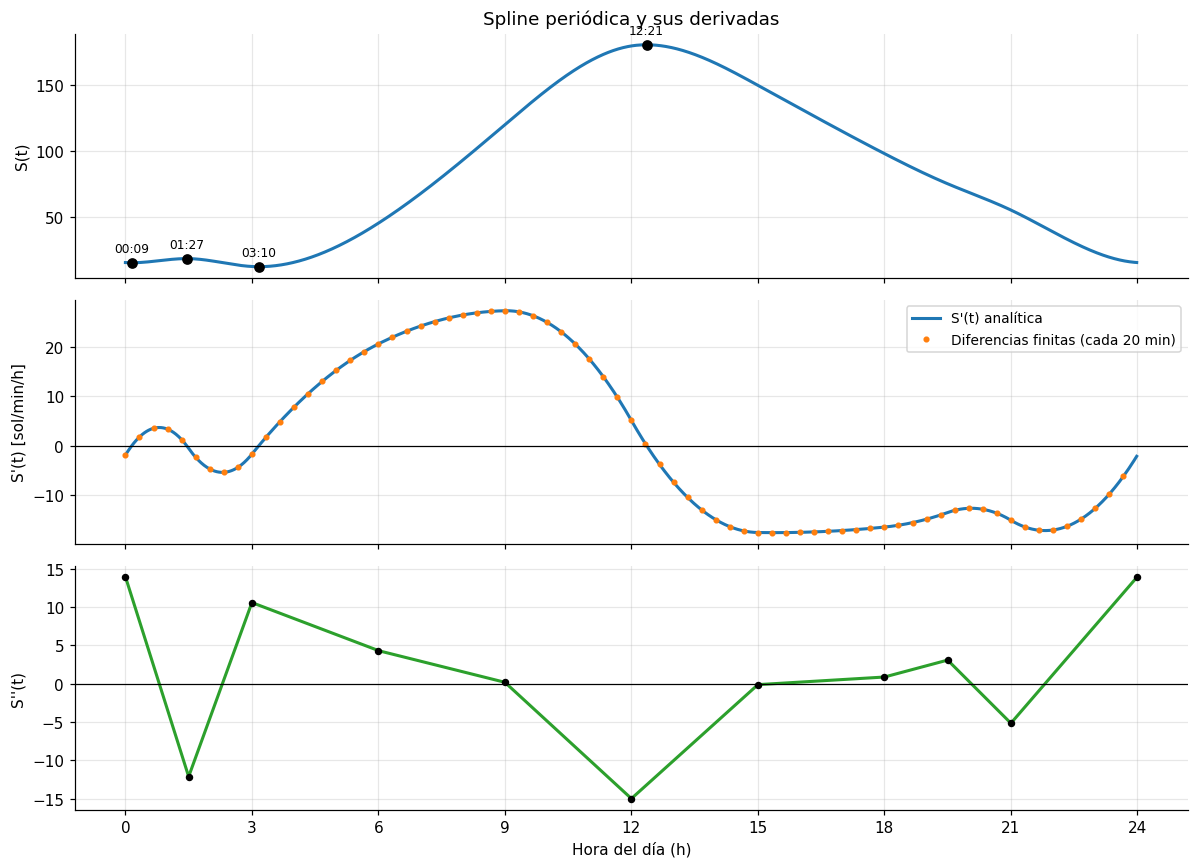

In [10]:
fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axs[0].plot(t_min, D, lw=2)
axs[0].scatter(crit, spline_per(crit), color="k", zorder=5)
for c in crit:
    axs[0].annotate(hhmm(c), (c, spline_per(c)), textcoords="offset points", xytext=(0, 7),
                    ha="center", fontsize=8)
axs[0].set_ylabel("S(t)")
axs[0].set_title("Spline periódica y sus derivadas")

axs[1].plot(t_min, dD_an, lw=2, label="S'(t) analítica")
axs[1].plot(t_min[::20], dD_fd[::20], "o", ms=3, label="Diferencias finitas (cada 20 min)")
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_ylabel("S'(t) [sol/min/h]")
axs[1].legend(fontsize=9)

axs[2].plot(t_min, d2S(t_min), lw=2, color="tab:green")
axs[2].scatter(t_nodos, d2S(t_nodos), color="k", s=15, zorder=5)
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_ylabel("S''(t)")
axs[2].set_xlabel("Hora del día (h)")
axs[2].set_xticks(range(0, 25, 3))
fig.tight_layout()
guardar(fig, "02_derivadas")
plt.show()

$S''(t)$ es lineal a trozos y **continua** (sin saltos en los nodos): evidencia visual de la continuidad $C^2$. Las diferencias finitas reproducen la derivada analítica con errores del orden de $h^2$.

## 5. Integración numérica — solicitudes totales del día

Como $D(t)$ está en solicitudes/min y $t$ en horas:

$$
N_{\text{día}} = 60 \int_0^{24} S(t)\,dt .
$$

Se compara la integral **exacta** de la spline (integración término a término de los cúbicos) contra trapecio y Simpson sobre la malla de 1 minuto, y contra la suma discreta de los 1440 minutos.

In [11]:
t_cerrado = np.linspace(0, T_CIERRE, MIN_DIA + 1)   # incluye t = 24 h para cuadraturas
D_cerrado = spline_per(t_cerrado)

N_exacto = 60 * spline_per.integrate(0, T_CIERRE)
metodos = {
    "Exacta (spline.integrate)": N_exacto,
    "Trapecio compuesto (h = 1 min)": 60 * trapezoid(D_cerrado, t_cerrado),
    "Simpson compuesto (h = 1 min)": 60 * simpson(D_cerrado, x=t_cerrado),
    "Suma de 1440 minutos": D.sum(),
    "Spline natural (exacta)": 60 * spline_nat.integrate(0, T_CIERRE),
    "Lineal a trozos (exacta)": 60 * trapezoid(y_nodos, t_nodos),
}
tabla_int = pd.DataFrame({"solicitudes/día": metodos})
tabla_int["error rel. vs exacta"] = (tabla_int["solicitudes/día"] - N_exacto).abs() / N_exacto
display(tabla_int.style.format({"solicitudes/día": "{:,.1f}", "error rel. vs exacta": "{:.2e}"}))

# Distribución por franjas horarias
franjas = {"Madrugada (00–06)": (0, 6), "Mañana (06–12)": (6, 12),
           "Tarde (12–18)": (12, 18), "Noche (18–24)": (18, 24)}
tabla_franjas = pd.DataFrame(
    {"solicitudes": {k: 60 * spline_per.integrate(a, b) for k, (a, b) in franjas.items()}})
tabla_franjas["% del día"] = 100 * tabla_franjas["solicitudes"] / N_exacto
tabla_franjas["promedio (sol/min)"] = tabla_franjas["solicitudes"] / 360
tabla_franjas.round(1)

,solicitudes/día,error rel. vs exacta
Exacta (spline.integrate),"121,823.8",0.00e+00
Trapecio compuesto (h = 1 min),"121,823.8",1.19e-16
Simpson compuesto (h = 1 min),"121,823.8",1.19e-16
Suma de 1440 minutos,"121,823.8",1.19e-16
Spline natural (exacta),"122,495.3",5.51e-03
Lineal a trozos (exacta),"121,770.0",4.42e-04


,solicitudes,% del día,promedio (sol/min)
Madrugada (00–06),6957.2,5.7,19.3
Mañana (06–12),42548.7,34.9,118.2
Tarde (12–18),52992.5,43.5,147.2
Noche (18–24),19325.4,15.9,53.7


Trapecio y Simpson con $h = 1$ min reproducen la integral exacta de la spline prácticamente a precisión de máquina. Las diferencias relevantes vienen del **modelo** (natural o lineal vs periódica), no de la cuadratura.

## 6. Detección del umbral crítico (150 solicitudes/min)

Dos enfoques complementarios:

1. **Exacto (continuo):** raíces de $S(t) - 150 = 0$ con `CubicSpline.solve` (resuelve el cúbico de cada tramo).
2. **Discreto (operativo):** minutos $k$ tales que $S(t_k) > 150$, que es lo que consume el algoritmo de despacho.

Además, el **exceso de demanda** sobre el umbral, $60\int (S(t) - 150)^+\,dt$, cuantifica cuántas solicitudes deben ser absorbidas por la reasignación preventiva.

In [12]:
def intervalos_sobre_umbral(mascara):
    # Agrupa índices consecutivos True en intervalos [inicio, fin] (inclusive).
    idx = np.flatnonzero(mascara)
    if idx.size == 0:
        return []
    cortes = np.flatnonzero(np.diff(idx) > 1)
    inicios = np.r_[idx[0], idx[cortes + 1]]
    fines = np.r_[idx[cortes], idx[-1]]
    return list(zip(inicios, fines))


def analizar_umbral(spline, tol=1e-9):
    raices = spline.solve(UMBRAL, extrapolate=False)
    raices = np.unique(np.round(raices[(raices >= 0) & (raices <= T_CIERRE)], 10))
    # Intervalos continuos donde S(t) > umbral (se prueba el punto medio entre raíces)
    bordes = np.r_[0.0, raices, T_CIERRE]
    tramos = [(a, b) for a, b in zip(bordes[:-1], bordes[1:])
              if b - a > 1e-9 and spline((a + b) / 2) > UMBRAL]
    exceso = sum(60 * (spline.integrate(a, b) - UMBRAL * (b - a)) for a, b in tramos)
    mascara = spline(t_min) > UMBRAL + tol
    return raices, tramos, mascara, exceso


resultados_umbral = {}
for nombre, s in [("periódica", spline_per), ("natural", spline_nat)]:
    raices, tramos, mascara, exceso = analizar_umbral(s)
    resultados_umbral[nombre] = (raices, mascara, exceso)
    print(f"── Spline {nombre} ──")
    print("  Cruces exactos S(t) = 150:", ", ".join(f"{r:.5f} h ({hhmm(r, True)})" for r in raices))
    for a, b in tramos:
        print(f"  Tramo continuo sobre el umbral: {hhmm(a, True)} → {hhmm(b, True)}  ({60*(b-a):.2f} min)")
    for i0, i1 in intervalos_sobre_umbral(mascara):
        print(f"  Minutos discretos > 150: k = {i0} … {i1}  ({curva['hora'][i0]} – {curva['hora'][i1]}), "
              f"{i1 - i0 + 1} minutos")
    print(f"  Exceso de demanda sobre el umbral: {exceso:,.0f} solicitudes\n")

raices_per, mascara_per, exceso_per = resultados_umbral["periódica"]
minutos_criticos = minutos[mascara_per]

── Spline periódica ──
  Cruces exactos S(t) = 150: 10.13916 h (10:08:21), 15.00000 h (15:00:00)
  Tramo continuo sobre el umbral: 10:08:21 → 15:00:00  (291.65 min)
  Minutos discretos > 150: k = 609 … 899  (10:09 – 14:59), 291 minutos
  Exceso de demanda sobre el umbral: 5,729 solicitudes

── Spline natural ──
  Cruces exactos S(t) = 150: 10.13851 h (10:08:19), 15.00000 h (15:00:00)
  Tramo continuo sobre el umbral: 10:08:19 → 15:00:00  (291.69 min)
  Minutos discretos > 150: k = 609 … 899  (10:09 – 14:59), 291 minutos
  Exceso de demanda sobre el umbral: 5,732 solicitudes



In [13]:
# Tabla operativa de minutos críticos (exportable al sistema de despacho)
criticos = curva.loc[mascara_per, ["minuto", "hora", "periódica"]].rename(
    columns={"periódica": "demanda (sol/min)"})
criticos["exceso (sol/min)"] = criticos["demanda (sol/min)"] - UMBRAL
criticos.to_csv(RAIZ / "data" / "minutos_criticos.csv", index=False)
print(f"{len(criticos)} minutos críticos exportados → data/minutos_criticos.csv")
pd.concat([criticos.head(3), criticos.iloc[[criticos['exceso (sol/min)'].argmax()]], criticos.tail(3)]).round(3)

291 minutos críticos exportados → data/minutos_criticos.csv


,minuto,hora,demanda (sol/min),exceso (sol/min)
609,609,10:09,150.263,0.263
610,610,10:10,150.665,0.665
611,611,10:11,151.066,1.066
742,742,12:22,180.893,30.893
897,897,14:57,150.882,0.882
898,898,14:58,150.588,0.588
899,899,14:59,150.294,0.294


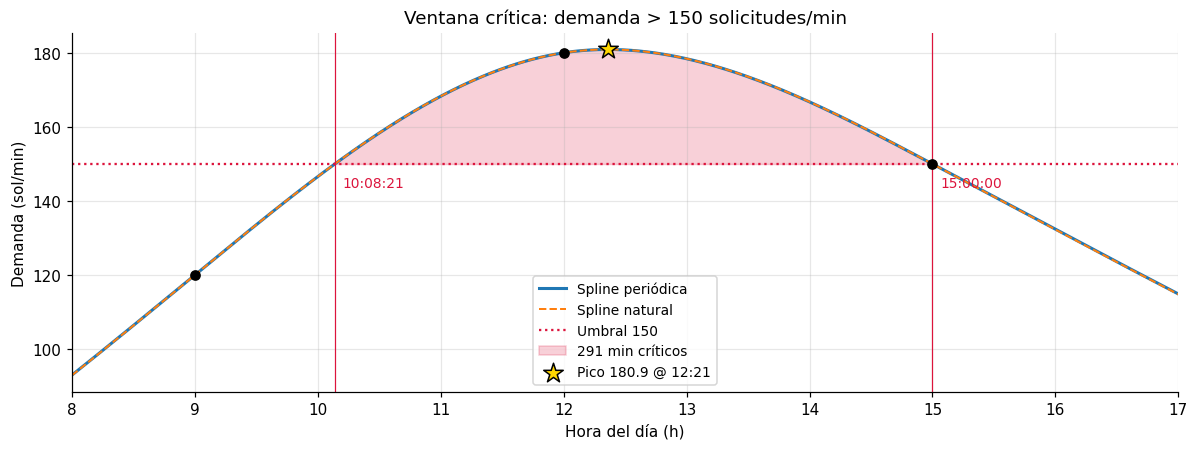

In [14]:
fig, ax = plt.subplots(figsize=(11, 4.2))
zoom = (t_min >= 8) & (t_min <= 17)
ax.plot(t_min[zoom], D[zoom], lw=2, label="Spline periódica")
ax.plot(t_min[zoom], curva["natural"][zoom], lw=1.3, ls="--", label="Spline natural")
ax.axhline(UMBRAL, color="crimson", ls=":", lw=1.5, label="Umbral 150")
ax.fill_between(t_min, UMBRAL, D, where=mascara_per, color="crimson", alpha=0.2,
                label=f"{mascara_per.sum()} min críticos")
for r in raices_per:
    ax.axvline(r, color="crimson", lw=0.8)
    ax.annotate(hhmm(r, True), (r, UMBRAL), textcoords="offset points", xytext=(5, -15), fontsize=9,
                color="crimson")
ax.scatter(t_pico, D_pico, marker="*", s=180, color="gold", edgecolor="k", zorder=6,
           label=f"Pico {D_pico:.1f} @ {hhmm(t_pico)}")
ax.scatter(t_nodos[4:7], y_nodos[4:7], color="k", zorder=5)
ax.set_xlim(8, 17)
ax.set_xlabel("Hora del día (h)")
ax.set_ylabel("Demanda (sol/min)")
ax.set_title("Ventana crítica: demanda > 150 solicitudes/min")
ax.legend(fontsize=9, loc="lower center")
fig.tight_layout()
guardar(fig, "03_umbral")
plt.show()

## 7. Mejora tecnológica — Filtro Predictivo de Corto Plazo

**Idea.** La spline periódica es el *perfil base* (lo que “normalmente” pasa a cada hora), pero la demanda real fluctúa (lluvia, eventos, trancones). Como los datos no son equidistantes no se ajusta un ARIMA; en su lugar, el filtro trabaja sobre la **desviación** respecto a la spline, que sí llega en un flujo uniforme de 1 minuto:

$$
r_t = y_t - S(t) \qquad \text{(residuo observado)}
$$

Se suaviza $r_t$ en línea con uno de estos estimadores:

| Método | Actualización |
|---|---|
| **SES** (suavizado exponencial simple) | $\hat r_t = \alpha\, r_t + (1-\alpha)\,\hat r_{t-1}$ |
| **Holt amortiguado** (nivel + tendencia) | $\ell_t = \alpha r_t + (1-\alpha)(\ell_{t-1} + \phi b_{t-1})$, $\;b_t = \beta(\ell_t - \ell_{t-1}) + (1-\beta)\phi b_{t-1}$ |
| **WMA** (media móvil ponderada, ventana $N$) | $\hat r_t = \dfrac{\sum_{j=1}^{N} j\, r_{t-N+j}}{\sum_{j=1}^{N} j}$ |

y la **proyección a $H = 30$ min** combina la forma conocida de la spline con la desviación actual:

$$
\hat y_{t+H} = S(t+H) + \hat r_{t+H\mid t}, \qquad
\hat r_{t+H\mid t} = \begin{cases} \hat r_t & \text{SES / WMA} \\ \ell_t + b_t \sum_{i=1}^{H}\phi^i & \text{Holt amortiguado} \end{cases}
$$

**Alerta:** se emite cuando $\hat y_{t+H} > 150$ durante `confirmacion` minutos consecutivos, y se cierra cuando baja de $150 - \text{histéresis}$ (evita alertas intermitentes por ruido).

```
 flujo 1 min ─► y_t ─┐
                     ├─► r_t = y_t − S(t) ─► [SES | Holt | WMA] ─► r̂ ─┐
 spline S(t) ────────┘                                                ├─► ŷ(t+30) = S(t+30) + r̂ ─► ¿> 150? ─► ALERTA
 spline S(t+30) ──────────────────────────────────────────────────────┘
```

### 7.1 Simulación del flujo de demanda en tiempo real

$$
y_t = \underbrace{S(t)}_{\text{perfil base}} + \underbrace{\textstyle\sum_j A_j\, e^{-\frac{1}{2}\left(\frac{t-c_j}{w_j}\right)^2}}_{\text{eventos imprevistos}} + \underbrace{u_t}_{\text{AR(1) lento}} + \underbrace{\varepsilon_t}_{\text{ruido rápido}},
\qquad u_t = \phi\, u_{t-1} + \eta_t
$$

- **Componente lenta** $u_t$ (AR(1), $\phi = 0.985$): desviaciones persistentes del día (clima, tráfico, festivos) que duran decenas de minutos.
- **Ruido rápido** $\varepsilon_t \sim N(0, 4^2)$: variabilidad minuto a minuto que el filtro debe suavizar.
- **Eventos imprevistos**: pulsos que la spline (construida con reportes históricos) no conoce.

In [15]:
EVENTOS = [  # (descripción, centro [h], ancho σ [h], amplitud [sol/min])
    ("Aguacero en hora pico matutina", 8.00, 0.60, 70),
    ("Salida de concierto (Movistar Arena)", 19.00, 0.50, 90),
]


def simular_flujo(spline, sigma_rapido=4.0, sigma_lento=1.2, phi=0.985, eventos=EVENTOS, semilla=2026):
    # Devuelve (observado, señal estructural = spline + eventos) para los 1440 minutos.
    rng = np.random.default_rng(semilla)
    base = spline(t_min)
    lento = np.zeros(MIN_DIA)
    for k in range(1, MIN_DIA):
        lento[k] = phi * lento[k - 1] + rng.normal(0, sigma_lento)
    ruido = lento + rng.normal(0, sigma_rapido, MIN_DIA)
    pulsos = sum((a * np.exp(-0.5 * ((t_min - c) / w) ** 2) for _, c, w, a in eventos),
                 np.zeros(MIN_DIA))
    senal = base + pulsos
    return np.clip(senal + ruido, 0, None), senal


y_obs, y_senal = simular_flujo(spline_per)
print(f"Desv. estándar de la fluctuación total: {np.std(y_obs - y_senal):.2f} sol/min")
for desc, c, w, a in EVENTOS:
    print(f"Evento: {desc:<40s} pico {hhmm(c)}  (+{a} sol/min sobre S = {spline_per(c):.1f})")

Desv. estándar de la fluctuación total: 7.41 sol/min
Evento: Aguacero en hora pico matutina           pico 08:00  (+70 sol/min sobre S = 93.0)
Evento: Salida de concierto (Movistar Arena)     pico 19:00  (+90 sol/min sobre S = 82.1)


### 7.2 Módulo `FiltroPredictivo`

Procesa una observación por minuto (modo *streaming*, sin mirar el futuro) y mantiene el estado de alerta.

In [16]:
class FiltroPredictivo:
    # Filtro de corto plazo: spline base + suavizado de la desviación + alertas.

    # metodo: "ses" | "holt" | "wma" | "spline" (sin filtro: solo el perfil base, referencia)

    def __init__(self, spline, metodo="ses", alpha=0.2, beta=0.05, phi=0.9, ventana=15,
                 horizonte=30, umbral=UMBRAL, histeresis=8.0, confirmacion=3,
                 verbose=True, periodo=24.0):
        assert metodo in {"ses", "holt", "wma", "spline"}
        self.S, self.metodo = spline, metodo
        self.alpha, self.beta, self.phi = alpha, beta, phi
        self.H, self.umbral, self.hist = horizonte, umbral, histeresis
        self.confirmacion, self.verbose, self.periodo = confirmacion, verbose, periodo
        self.buffer = deque(maxlen=ventana)
        self.pesos = np.arange(1, ventana + 1, dtype=float)
        self.nivel = None
        self.tend = 0.0
        self.factor_holt = sum(phi ** i for i in range(1, horizonte + 1))
        self.en_alerta, self.racha = False, 0
        self.eventos = []      # bitácora de alertas

    def _base(self, minuto):
        return float(self.S((minuto / 60.0) % self.periodo))   # envuelve al día siguiente

    def _suavizar(self, r):
        if self.metodo == "spline":
            return 0.0
        if self.metodo == "wma":
            self.buffer.append(r)
            w = self.pesos[-len(self.buffer):]
            return float(np.dot(w, self.buffer) / w.sum())
        if self.nivel is None:
            self.nivel = r
            return r
        if self.metodo == "ses":
            self.nivel = self.alpha * r + (1 - self.alpha) * self.nivel
            return self.nivel
        # Holt amortiguado
        previo = self.nivel
        self.nivel = self.alpha * r + (1 - self.alpha) * (previo + self.phi * self.tend)
        self.tend = self.beta * (self.nivel - previo) + (1 - self.beta) * self.phi * self.tend
        return self.nivel + self.factor_holt * self.tend

    def actualizar(self, minuto, y):
        # Ingresa la observación del minuto actual y devuelve la proyección a t + H.
        r = y - self._base(minuto)
        r_proy = self._suavizar(r)
        objetivo = minuto + self.H
        y_proy = max(0.0, self._base(objetivo) + r_proy)

        # Lógica de alerta con confirmación + histéresis
        self.racha = self.racha + 1 if y_proy > self.umbral else 0
        if not self.en_alerta and self.racha >= self.confirmacion:
            self.en_alerta = True
            self._registrar("INICIO", minuto, objetivo, y_proy)
        elif self.en_alerta and y_proy < self.umbral - self.hist:
            self.en_alerta = False
            self._registrar("FIN", minuto, objetivo, y_proy)
        return {"minuto": minuto, "objetivo": objetivo, "y_obs": y, "residuo": r,
                "residuo_suav": r_proy, "y_proy": y_proy, "alerta": self.en_alerta}

    def _registrar(self, tipo, minuto, objetivo, y_proy):
        self.eventos.append({"tipo": tipo, "minuto_emision": minuto, "minuto_objetivo": objetivo,
                             "y_proy": y_proy})
        if not self.verbose:
            return
        t_e, t_o = hhmm(minuto / 60), hhmm((objetivo % MIN_DIA) / 60)
        if tipo == "INICIO":
            print(f"[{t_e}] 🚨 ALERTA: demanda proyectada para las {t_o} = {y_proy:6.1f} sol/min "
                  f"(> {self.umbral:.0f}, exceso +{y_proy - self.umbral:.1f}). "
                  f"→ Reasignar flota preventivamente.")
        else:
            print(f"[{t_e}] ✅ FIN DE ALERTA: proyección para las {t_o} = {y_proy:6.1f} sol/min "
                  f"(< {self.umbral - self.hist:.0f}).")


def correr_filtro(y, spline=spline_per, **kw):
    # Simula el flujo minuto a minuto y devuelve el historial (DataFrame) y el filtro.
    filtro = FiltroPredictivo(spline, **kw)
    hist = pd.DataFrame([filtro.actualizar(k, float(y[k])) for k in range(len(y))])
    return hist, filtro

### 7.3 Ejecución en tiempo real con alertas en consola

In [17]:
METODO, ALPHA, BETA, PHI = "holt", 0.2, 0.05, 0.9     # suavizado exponencial doble amortiguado
print(f"Filtro: Spline + {METODO.upper()}  α = {ALPHA}  β = {BETA}  φ = {PHI}  "
      f"horizonte = 30 min  umbral = {UMBRAL:.0f}\n")
hist, filtro = correr_filtro(y_obs, metodo=METODO, alpha=ALPHA, beta=BETA, phi=PHI)
bitacora = pd.DataFrame(filtro.eventos)

Filtro: Spline + HOLT  α = 0.2  β = 0.05  φ = 0.9  horizonte = 30 min  umbral = 150

[07:33] 🚨 ALERTA: demanda proyectada para las 08:03 =  150.8 sol/min (> 150, exceso +0.8). → Reasignar flota preventivamente.
[15:19] ✅ FIN DE ALERTA: proyección para las 15:49 =  140.1 sol/min (< 142).
[18:47] 🚨 ALERTA: demanda proyectada para las 19:17 =  154.1 sol/min (> 150, exceso +4.1). → Reasignar flota preventivamente.
[19:16] ✅ FIN DE ALERTA: proyección para las 19:46 =  140.5 sol/min (< 142).


### 7.4 Evaluación del pronóstico a 30 minutos

Se compara $\hat y_{t+30}$ con lo realmente observado en $t+30$, frente a referencias sin filtro:

- **Solo spline:** $\hat y_{t+30} = S(t+30)$ (ignora la realidad del momento).
- **Persistencia:** $\hat y_{t+30} = y_t$ (ignora la forma diaria).
- **SES sin spline:** suavizado exponencial directo de $y_t$ (ignora la forma diaria, pero filtra ruido).

La métrica relevante para el negocio no es solo el RMSE, sino **si la alerta llega antes** de que la demanda real cruce 150, en particular ante eventos que el perfil histórico no contiene.

In [18]:
H = 30


def metricas(pred, real):
    e = pred - real
    return {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "Error máx.": np.max(np.abs(e))}


k_eval = np.arange(MIN_DIA - H)              # objetivos dentro del mismo día
real = y_obs[k_eval + H]

# Referencias
ses_directo = np.empty(MIN_DIA)
ses_directo[0] = y_obs[0]
for k in range(1, MIN_DIA):
    ses_directo[k] = ALPHA * y_obs[k] + (1 - ALPHA) * ses_directo[k - 1]

pronosticos = {
    "Solo spline S(t+30)": spline_per(t_min[k_eval + H]),
    "Persistencia y(t)": y_obs[k_eval],
    "SES sin spline": ses_directo[k_eval],
}
config = {"Spline + SES (α=0.2)": dict(metodo="ses", alpha=0.2),
          "Spline + WMA (N=15)": dict(metodo="wma", ventana=15),
          "Spline + Holt amortiguado": dict(metodo="holt", alpha=0.2, beta=0.05, phi=0.9)}
historiales = {}
for nombre, kw in config.items():
    h_, f_ = correr_filtro(y_obs, verbose=False, **kw)
    historiales[nombre] = (h_, f_)
    pronosticos[nombre] = h_["y_proy"].to_numpy()[k_eval]

tabla_pron = pd.DataFrame({n: metricas(p, real) for n, p in pronosticos.items()}).T
ref = tabla_pron.loc["Solo spline S(t+30)", "RMSE"]
tabla_pron["Mejora RMSE vs solo spline"] = 1 - tabla_pron["RMSE"] / ref
mejor = tabla_pron.loc[tabla_pron.index.str.startswith("Spline +"), "RMSE"].idxmin()
print(f"Mejor filtro: {mejor} → RMSE {tabla_pron.loc[mejor, 'RMSE']:.2f} "
      f"({tabla_pron.loc[mejor, 'Mejora RMSE vs solo spline']:.1%} menos error que la spline sola)")
tabla_pron.style.format({"RMSE": "{:.2f}", "MAE": "{:.2f}", "Error máx.": "{:.2f}",
                         "Mejora RMSE vs solo spline": "{:+.1%}"})

Mejor filtro: Spline + Holt amortiguado → RMSE 15.80 (28.6% menos error que la spline sola)


,RMSE,MAE,Error máx.,Mejora RMSE vs solo spline
Solo spline S(t+30),22.13,12.83,87.79,+0.0%
Persistencia y(t),17.74,12.81,69.74,+19.8%
SES sin spline,18.92,13.52,70.55,+14.5%
Spline + SES (α=0.2),16.67,11.06,62.83,+24.6%
Spline + WMA (N=15),16.95,11.22,64.06,+23.4%
Spline + Holt amortiguado,15.80,10.64,62.56,+28.6%


In [19]:
# Sensibilidad del parámetro α (SES) y de la ventana N (WMA)
sens = []
for a in [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]:
    h_, _ = correr_filtro(y_obs, metodo="ses", alpha=a, verbose=False)
    sens.append({"método": "SES", "parámetro": f"α = {a}", **metricas(h_["y_proy"].to_numpy()[k_eval], real)})
for n in [5, 10, 15, 30, 60]:
    h_, _ = correr_filtro(y_obs, metodo="wma", ventana=n, verbose=False)
    sens.append({"método": "WMA", "parámetro": f"N = {n}", **metricas(h_["y_proy"].to_numpy()[k_eval], real)})
for a, b, ph in [(0.1, 0.02, 0.95), (0.2, 0.05, 0.9), (0.3, 0.05, 0.9), (0.2, 0.1, 0.85)]:
    h_, _ = correr_filtro(y_obs, metodo="holt", alpha=a, beta=b, phi=ph, verbose=False)
    sens.append({"método": "Holt", "parámetro": f"α={a}, β={b}, φ={ph}",
                 **metricas(h_["y_proy"].to_numpy()[k_eval], real)})
pd.DataFrame(sens).round(2)

,método,parámetro,RMSE,MAE,Error máx.
0,SES,α = 0.05,19.37,12.74,72.96
1,SES,α = 0.1,17.85,11.72,67.08
2,SES,α = 0.2,16.67,11.06,62.83
3,SES,α = 0.3,16.22,10.84,60.61
4,SES,α = 0.5,15.87,10.72,61.15
5,SES,α = 0.8,15.79,10.80,62.07
6,WMA,N = 5,15.95,10.74,60.92
7,WMA,N = 10,16.44,10.95,62.70
8,WMA,N = 15,16.95,11.22,64.06
9,WMA,N = 30,18.32,11.96,68.54


In [20]:
# Anticipación de las alertas frente a los episodios reales (señal estructural > 150)
S_base = spline_per(t_min)


def evaluar_alertas(hist, senal=y_senal):
    episodios = intervalos_sobre_umbral(senal > UMBRAL)
    alertas = intervalos_sobre_umbral(hist["alerta"].to_numpy())   # en minuto de emisión
    filas, usadas, fin_previo = [], set(), None
    for e0, e1 in episodios:
        # alertas activas durante el episodio o que terminaron hasta 60 min antes
        cand = [j for j, (a0, a1) in enumerate(alertas) if a0 <= e1 and a1 >= e0 - 60]
        usadas.update(cand)
        a0 = min(alertas[j][0] for j in cand) if cand else None
        filas.append({
            "episodio real (señal > 150)": f"{hhmm(e0/60)} – {hhmm(e1/60)}",
            "origen": "evento imprevisto" if S_base[e0:e1 + 1].max() <= UMBRAL else "pico estructural (spline)",
            "duración (min)": e1 - e0 + 1,
            "alerta desde": hhmm(a0 / 60) if a0 is not None else "NO DETECTADO",
            "anticipación (min)": (e0 - a0) if a0 is not None else np.nan,
            "nota": ("alerta continua desde el episodio anterior"
                     if a0 is not None and fin_previo is not None and a0 <= fin_previo else ""),
        })
        fin_previo = e1
    falsas = [f"{hhmm(a0/60)}–{hhmm(a1/60)}" for j, (a0, a1) in enumerate(alertas) if j not in usadas]
    return pd.DataFrame(filas), falsas


tabla_alertas, falsas = evaluar_alertas(hist)
display(tabla_alertas)
print("Alertas sin episodio real asociado (falsas alarmas):", falsas or "ninguna")

,episodio real (señal > 150),origen,duración (min),alerta desde,anticipación (min),nota
0,07:45 – 08:38,evento imprevisto,54,07:33,12,
1,10:09 – 15:00,pico estructural (spline),292,07:33,156,alerta continua desde el episodio anterior
2,18:34 – 19:19,evento imprevisto,46,18:47,-13,


Alertas sin episodio real asociado (falsas alarmas): ninguna


In [21]:
# Desempeño de alertas por método (incluye la referencia sin filtro)
comp = {"Solo spline (sin filtro)": dict(metodo="spline"), **config}
filas = []
for nombre, kw in comp.items():
    h_, f_ = correr_filtro(y_obs, verbose=False, **kw)
    ta, fa = evaluar_alertas(h_)
    imp = ta[ta["origen"] == "evento imprevisto"]
    filas.append({"método": nombre,
                  "alertas emitidas": sum(e["tipo"] == "INICIO" for e in f_.eventos),
                  "eventos imprevistos detectados": f"{imp['anticipación (min)'].notna().sum()}/{len(imp)}",
                  "anticipación media (min)": ta["anticipación (min)"].mean(),
                  "falsas alarmas": len(fa)})
tabla_alertas_metodos = pd.DataFrame(filas).set_index("método")
tabla_alertas_metodos.round(1)

,alertas emitidas,eventos imprevistos detectados,anticipación media (min),falsas alarmas
método,,,,
Solo spline (sin filtro),1,0/2,28.0,0
Spline + SES (α=0.2),2,2/2,47.0,0
Spline + WMA (N=15),2,2/2,46.7,0
Spline + Holt amortiguado,2,2/2,51.7,0


La spline sola anticipa perfectamente el pico estructural del mediodía (lo “conoce” de los datos históricos), pero **es ciega ante eventos imprevistos**. El filtro predictivo conserva esa anticipación estructural y además detecta los eventos en cuanto la desviación $r_t$ empieza a crecer. Anticipaciones negativas indican que la alerta llegó poco después de que la señal cruzara 150: ante un evento sin precedentes el filtro solo puede reaccionar a la evidencia observada, pero reacciona en pocos minutos, mientras que la spline sola nunca alerta.

### 7.5 Gráficas de la simulación

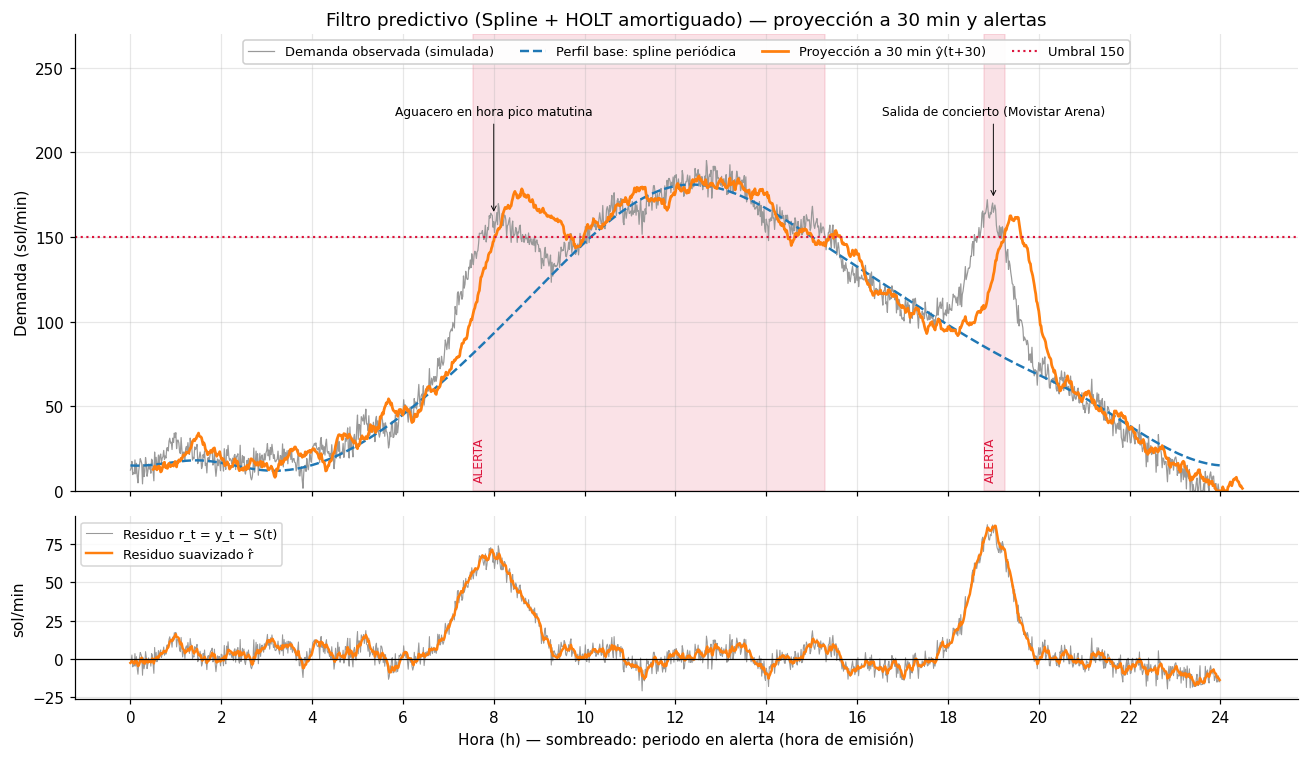

In [22]:
def graficar_simulacion(hist, y_obs, y_senal, titulo, nombre=None, eventos=EVENTOS):
    proy_t = hist["objetivo"].to_numpy() / 60          # proyección dibujada en su hora objetivo
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1.2]})
    ax.plot(t_min, y_obs, color="0.6", lw=0.8, label="Demanda observada (simulada)")
    ax.plot(t_min, spline_per(t_min), color="tab:blue", lw=1.6, ls="--", label="Perfil base: spline periódica")
    ax.plot(proy_t, hist["y_proy"], color="tab:orange", lw=1.8, label="Proyección a 30 min ŷ(t+30)")
    ax.axhline(UMBRAL, color="crimson", ls=":", lw=1.4, label="Umbral 150")
    for i0, i1 in intervalos_sobre_umbral(hist["alerta"].to_numpy()):
        ax.axvspan(i0 / 60, i1 / 60, color="crimson", alpha=0.12)
        ax.annotate("ALERTA", (i0 / 60, 5), fontsize=8, color="crimson", rotation=90, va="bottom")
    for desc, c, w, a in eventos:
        if a > 0:
            ax.annotate(desc, (c, spline_per(c) + a), ha="center", fontsize=8, xytext=(c, 222),
                        arrowprops=dict(arrowstyle="->", lw=0.6))
    ax.set_ylabel("Demanda (sol/min)")
    ax.set_ylim(0, 270)
    ax.set_title(titulo)
    ax.legend(fontsize=8.5, loc="upper center", ncol=4, framealpha=0.95)

    ax2.plot(t_min, hist["residuo"], color="0.6", lw=0.7, label="Residuo r_t = y_t − S(t)")
    ax2.plot(t_min, hist["residuo_suav"], color="tab:orange", lw=1.6, label="Residuo suavizado r̂")
    ax2.axhline(0, color="k", lw=0.8)
    ax2.set_ylabel("sol/min")
    ax2.set_xlabel("Hora (h) — sombreado: periodo en alerta (hora de emisión)")
    ax2.set_xticks(range(0, 25, 2))
    ax2.legend(fontsize=8.5, loc="upper left")
    fig.tight_layout()
    if nombre:
        guardar(fig, nombre)
    plt.show()


graficar_simulacion(hist, y_obs, y_senal, f"Filtro predictivo (Spline + {METODO.upper()} amortiguado) "
                    "— proyección a 30 min y alertas", "04_filtro_predictivo")

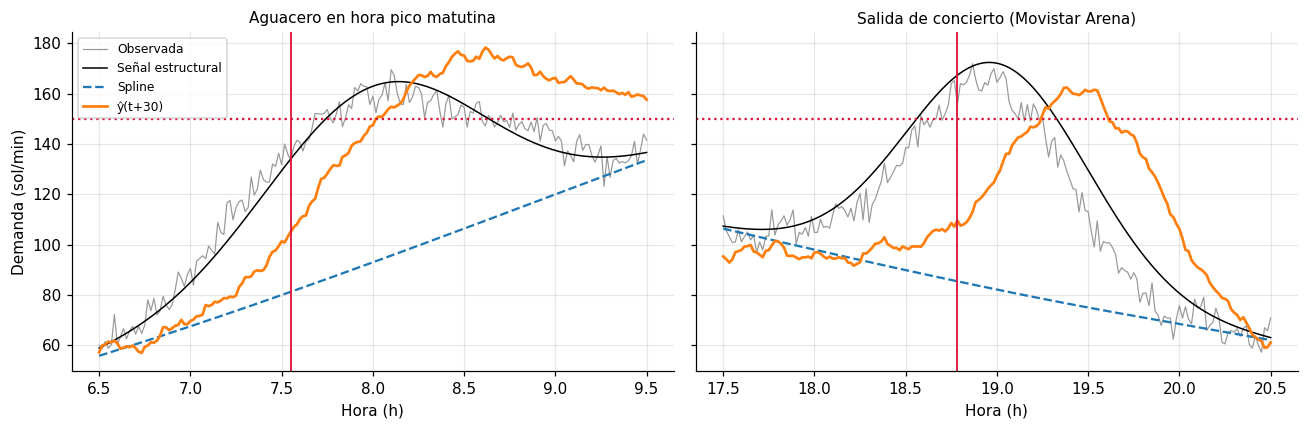

In [23]:
# Zoom en los eventos: ¿con cuánta anticipación avisa el filtro?
fig, axs = plt.subplots(1, len(EVENTOS), figsize=(12, 4), sharey=True)
for ax, (desc, c, w, a) in zip(np.atleast_1d(axs), EVENTOS):
    m = (t_min >= c - 1.5) & (t_min <= c + 1.5)
    ax.plot(t_min[m], y_obs[m], color="0.6", lw=0.8, label="Observada")
    ax.plot(t_min[m], y_senal[m], color="k", lw=1, label="Señal estructural")
    ax.plot(t_min[m], spline_per(t_min[m]), "--", color="tab:blue", label="Spline")
    hm = hist[(hist["objetivo"] / 60 >= c - 1.5) & (hist["objetivo"] / 60 <= c + 1.5)]
    ax.plot(hm["objetivo"] / 60, hm["y_proy"], color="tab:orange", lw=1.8, label="ŷ(t+30)")
    ax.axhline(UMBRAL, color="crimson", ls=":")
    for e in filtro.eventos:
        if e["tipo"] == "INICIO" and abs(e["minuto_emision"] / 60 - c) < 1.5:
            ax.axvline(e["minuto_emision"] / 60, color="crimson", lw=1.2)
            ax.annotate(f"alerta {hhmm(e['minuto_emision']/60)}", (e["minuto_emision"] / 60, 40),
                        rotation=90, fontsize=8, color="crimson", xytext=(-10, 0),
                        textcoords="offset points")
    ax.set_title(desc, fontsize=10)
    ax.set_xlabel("Hora (h)")
np.atleast_1d(axs)[0].set_ylabel("Demanda (sol/min)")
np.atleast_1d(axs)[0].legend(fontsize=8)
fig.tight_layout()
guardar(fig, "05_zoom_eventos")
plt.show()

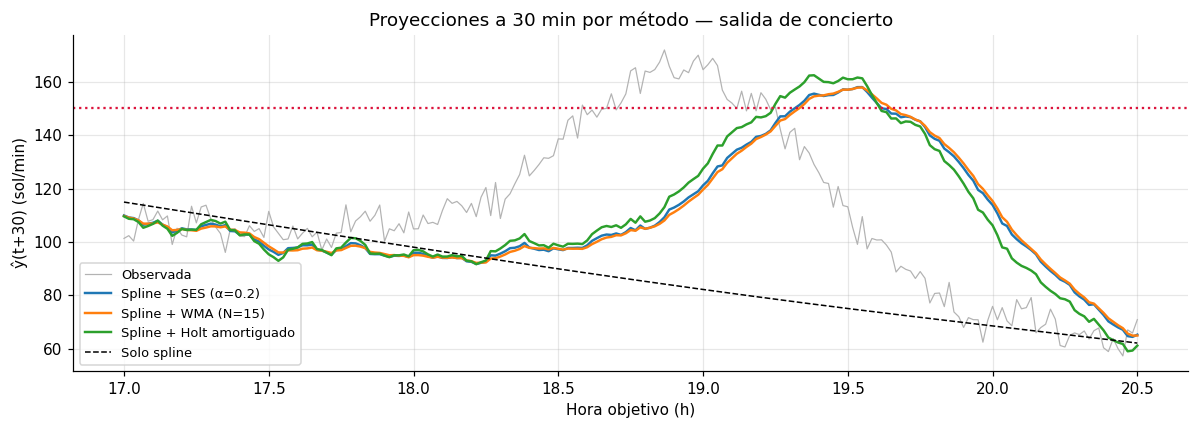

In [24]:
# Comparación visual de los tres métodos de suavizado alrededor del concierto
c = EVENTOS[1][1]
fig, ax = plt.subplots(figsize=(11, 4))
m = (t_min >= c - 2) & (t_min <= c + 1.5)
ax.plot(t_min[m], y_obs[m], color="0.7", lw=0.8, label="Observada")
for nombre, (h_, _) in historiales.items():
    hm = h_[(h_["objetivo"] / 60 >= c - 2) & (h_["objetivo"] / 60 <= c + 1.5)]
    ax.plot(hm["objetivo"] / 60, hm["y_proy"], lw=1.6, label=nombre)
ax.plot(t_min[m], spline_per(t_min[m]), "--", color="k", lw=1, label="Solo spline")
ax.axhline(UMBRAL, color="crimson", ls=":")
ax.set_xlabel("Hora objetivo (h)")
ax.set_ylabel("ŷ(t+30) (sol/min)")
ax.set_title("Proyecciones a 30 min por método — salida de concierto")
ax.legend(fontsize=8.5)
fig.tight_layout()
guardar(fig, "06_comparacion_metodos")
plt.show()

### 7.6 Simulador interactivo

Mueve los controles para ver cómo cambian la proyección y las alertas (requiere `ipywidgets`, incluido en `jupyter`).

In [25]:
try:
    from ipywidgets import Dropdown, FloatSlider, IntSlider, interact

    @interact(metodo=Dropdown(options=["holt", "ses", "wma", "spline"], value="holt", description="Método"),
              alpha=FloatSlider(value=0.2, min=0.02, max=0.9, step=0.02, description="α (SES/Holt)"),
              ventana=IntSlider(value=15, min=3, max=60, description="N (WMA)"),
              sigma=FloatSlider(value=4.0, min=0, max=12, step=0.5, description="σ rápido"),
              amp_concierto=IntSlider(value=80, min=0, max=150, step=5, description="Concierto"),
              semilla=IntSlider(value=2026, min=0, max=5000, description="Semilla"))
    def simulador(metodo, alpha, ventana, sigma, amp_concierto, semilla):
        ev = [EVENTOS[0], (EVENTOS[1][0], EVENTOS[1][1], EVENTOS[1][2], amp_concierto)]
        yo, ys = simular_flujo(spline_per, sigma_rapido=sigma, eventos=ev, semilla=semilla)
        h_, f_ = correr_filtro(yo, metodo=metodo, alpha=alpha, ventana=ventana, verbose=True)
        rm = metricas(h_["y_proy"].to_numpy()[k_eval], yo[k_eval + H])["RMSE"]
        print(f"\nRMSE pronóstico 30 min: {rm:.2f} sol/min — alertas emitidas: "
              f"{sum(e['tipo'] == 'INICIO' for e in f_.eventos)}")
        graficar_simulacion(h_, yo, ys, f"Simulador — {metodo.upper()}", eventos=ev)
except ImportError:
    print("ipywidgets no disponible: instale con `uv add ipywidgets` para usar el simulador.")

interactive(children=(Dropdown(description='Método', options=('holt', 'ses', 'wma', 'spline'), value='holt'), …

## 8. Resumen de resultados (insumo para el reporte y el pitch)

In [26]:
imp = tabla_alertas[tabla_alertas["origen"] == "evento imprevisto"]
ref_imp = tabla_alertas_metodos.loc["Solo spline (sin filtro)", "eventos imprevistos detectados"]
resumen = pd.Series({
    "Pico de demanda (sol/min)": f"{D_pico:.2f} a las {hhmm(t_pico, True)}",
    "Demanda mínima (sol/min)": f"{D.min():.2f} a las {curva['hora'][D.argmin()]}",
    "Solicitudes totales del día": f"{N_exacto:,.0f}",
    "Ventana crítica (> 150)": f"{hhmm(raices_per[0], True)} – {hhmm(raices_per[-1], True)}",
    "Minutos críticos (malla de 1 min)": f"{mascara_per.sum()} min (k = {minutos_criticos[0]} … {minutos_criticos[-1]})",
    "Exceso sobre umbral": f"{exceso_per:,.0f} solicitudes",
    "Máx. rampa de subida": f"{dD_an.max()/60:.3f} sol/min por minuto a las {curva['hora'][dD_an.argmax()]}",
    "Mejor pronóstico a 30 min": f"{mejor} (RMSE {tabla_pron.loc[mejor, 'RMSE']:.2f})",
    "Mejora RMSE vs solo spline": f"{tabla_pron.loc[mejor, 'Mejora RMSE vs solo spline']:.1%}",
    "Eventos imprevistos detectados": f"{imp['anticipación (min)'].notna().sum()}/{len(imp)} (solo spline: {ref_imp})",
    **{f"Alerta episodio {r['episodio real (señal > 150)']}": (
        f"desde {r['alerta desde']} ({r['anticipación (min)']:+.0f} min) {r['nota']}".strip()
        if r["alerta desde"] != "NO DETECTADO" else "no detectado")
       for _, r in tabla_alertas.iterrows()},
    "Falsas alarmas": str(len(falsas)),
    "Figuras exportadas": str(FIG_DIR.relative_to(RAIZ)),
}, name="valor")
resumen.to_frame()

,valor
Pico de demanda (sol/min),180.89 a las 12:21:34
Demanda mínima (sol/min),11.86 a las 03:10
Solicitudes totales del día,"121,824"
Ventana crítica (> 150),10:08:21 – 15:00:00
Minutos críticos (malla de 1 min),291 min (k = 609 … 899)
Exceso sobre umbral,"5,729 solicitudes"
Máx. rampa de subida,0.456 sol/min por minuto a las 09:02
Mejor pronóstico a 30 min,Spline + Holt amortiguado (RMSE 15.80)
Mejora RMSE vs solo spline,28.6%
Eventos imprevistos detectados,2/2 (solo spline: 0/2)
